# Global Unicorn Companies Analysis

Analysis of 1,205 privately held start-ups valued at $1 billion or more: where they are, which sectors they are in, how their valuations are distributed, and how unicorn creation changed over time.

Run from the repository root. Figures are written to `figures/`. Sections 1 to 5 are the original analysis; **section 6 checks the conclusions against the data** and corrects a few things found along the way.

## 1. UNDERSTANDING THE DATASET

In [1]:
# Load necessary libraries
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs('figures', exist_ok=True)

# Display all columns and avoid scientific notation
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# Load the raw dataset (valuations still carry '$' signs, dates are text)
df = pd.read_csv("data/global_unicorns_data.csv")

# Preview the dataset
df.head()

,Company,Valuation ($B),Date Joined,Country,City,Industry,Select Investors
0,ByteDance,$140.00,4/7/2017,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S..."
1,SpaceX,$127.00,12/1/2012,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen..."
2,SHEIN,$100.00,7/3/2018,China,Shenzhen,E-commerce & direct-to-consumer,"Tiger Global Management, Sequoia Capital China..."
3,Stripe,$95.00,1/23/2014,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG"
4,Canva,$40.00,1/8/2018,Australia,Surry Hills,Internet software & services,"Sequoia Capital China, Blackbird Ventures, Mat..."


In [2]:
# Check for duplicates
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

Number of duplicate rows: 0


## Dataset Overview

In [3]:
# Get basic information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1205 entries, 0 to 1204
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Company           1205 non-null   object
 1   Valuation ($B)    1205 non-null   object
 2   Date Joined       1205 non-null   object
 3   Country           1205 non-null   object
 4   City              1188 non-null   object
 5   Industry          1205 non-null   object
 6   Select Investors  1204 non-null   object
dtypes: object(7)
memory usage: 66.0+ KB


In [4]:
# Get basic statistics of all columns
df.describe(include='all')

,Company,Valuation ($B),Date Joined,Country,City,Industry,Select Investors
count,1205,1205,1205,1205,1188,1205,1204
unique,1202,227,716,49,283,16,1187
top,Branch,$1.00,7/13/2021,United States,San Francisco,Fintech,Sequoia Capital
freq,2,270,9,651,169,252,3


## 2. DATA CLEANING
In this section, we clean and prepare the dataset for analysis by ensuring proper formats and handling missing values.

**Goal:** Ensure data consistency by:
- Converting 'Valuation' from string to float
- Formatting date columns
- Handling missing values
- Confirming data retention

**Valuation Formatting:**  
We removed dollar signs and commas from the `Valuation ($B)` column and converted it into a numeric format (`float`) to allow for mathematical operations.

**Date Parsing:**  
The `Date Joined` column is converted to datetime format. We also extract the year into a new column `Year Joined` to support time-based analysis (e.g., trends over time).

**City Column:**  
Missing values in the `City` column are filled with `'Unknown'` to preserve those rows in the dataset and avoid accidental data loss.

**Select Investors Column:**  
One missing value in `Select Investors` was filled with `'Not disclosed'` to ensure consistency and prevent errors during visualizations or string-based analysis.

**Note:**  
We did not drop any rows. All 1,205 unicorn entries were retained to preserve completeness. One missing value in the `Select Investors` column was filled with `'Not disclosed'` to maintain consistency.

In [5]:
# Convert valuation to numeric
df['Valuation ($B)'] = df['Valuation ($B)'].replace(r'[\$,]', '', regex=True).astype(float)

# Convert 'Date Joined' to datetime and extract year
df['Date Joined'] = pd.to_datetime(df['Date Joined'], errors='coerce')
df['Year Joined'] = df['Date Joined'].dt.year

# Fill missing cities with 'Unknown'
df['City'] = df['City'].fillna('Unknown')

# Check for any remaining missing values
df.isnull().sum()

# Fill missing 'Select Investors' with a placeholder
# This prevents errors in analysis/visuals and ensures consistency in the dataset.
# Since there's only one missing value, we'll use 'Not disclosed' as a safe and neutral placeholder.
df['Select Investors'] = df['Select Investors'].fillna('Not disclosed')

print(df.isnull().sum())

Company             0
Valuation ($B)      0
Date Joined         0
Country             0
City                0
Industry            0
Select Investors    0
Year Joined         0
dtype: int64


**Two further fixes (added after checking the data).** The industry label `Artificial Intelligence` appears in a different capitalisation for 11 rows, which splits one sector into two. One row has its country and city swapped. Both are corrected here, before the features are built.

In [6]:
# Two further inconsistencies found while checking the data (see section 6.1):
# 1) 'Artificial Intelligence' (11 rows) and 'Artificial intelligence' (79 rows) are the same industry
df['Industry'] = df['Industry'].replace({'Artificial Intelligence': 'Artificial intelligence'})

# 2) One row has Country and City swapped ('London' / 'United Kingdom')
swapped = (df['Country'] == 'London') & (df['City'] == 'United Kingdom')
df.loc[swapped, ['Country', 'City']] = ['United Kingdom', 'London']

print('Industries now:', df['Industry'].nunique(), '| countries now:', df['Country'].nunique())

Industries now: 15 | countries now: 48


## 3. FEATURE ENGINEERING
To enrich our analysis, we created new columns based on existing data.

**Goal:** Add new derived features that help analysis.
- Valuation category
- Region grouping
- Top 5 industry flag
- Boom period tagging

**Valuation Category:**  
Categorized unicorns into groups based on their valuation: `1–2B`, `2–5B`, `5–10B`, and `10B+`.

**Region Grouping:**  
Countries were grouped into broader regions: `Americas`, `Asia`, `Europe`, and `Other`. This allows us to analyze geographic patterns more easily.

**Top Industry Flag:**  
Flagged companies that fall into the 5 most common industries to help highlight dominant sectors.

**Boom Period Tag:**  
Classified each unicorn by when it joined the unicorn list: those that joined in 2020–2021 were tagged as `"Boom (2020–2021)"`, others as `"Pre-Boom"` or further refined using a `Period Tag`.


In [7]:
# 1. Categorize Valuation Levels
def categorize_valuation(val):
    if val < 2:
        return '1–2B'
    elif val < 5:
        return '2–5B'
    elif val < 10:
        return '5–10B'
    else:
        return '10B+'

df['Valuation Category'] = df['Valuation ($B)'].apply(categorize_valuation)

# 2. Group Countries into Broad Regions
europe = ['Germany', 'France', 'United Kingdom', 'Sweden', 'Netherlands', 'Spain']
asia = ['China', 'India', 'South Korea', 'Singapore', 'Indonesia', 'Japan']
americas = ['United States', 'Canada', 'Brazil', 'Mexico']

def map_region(country):
    if country in europe:
        return 'Europe'
    elif country in asia:
        return 'Asia'
    elif country in americas:
        return 'Americas'
    else:
        return 'Other'

df['Region'] = df['Country'].apply(map_region)

# 3. Flag Top 5 Industries
top_industries = df['Industry'].value_counts().head(5).index.tolist()
df['Top Industry Flag'] = df['Industry'].apply(lambda x: 'Top 5' if x in top_industries else 'Other')

# 4. Tag Boom Years (we keep this as we want both)
df['Boom Period'] = df['Year Joined'].apply(lambda x: 'Boom (2020–2021)' if x in [2020, 2021] else 'Pre-Boom')

# 5. More granular period categorization
def tag_period(year):
    if year < 2015:
        return 'Pre-2015'
    elif year < 2020:
        return '2015–2019'
    elif year <= 2021:
        return 'Boom (2020–2021)'
    else:
        return 'Post-2021'

df['Period Tag'] = df['Year Joined'].apply(tag_period)

print(df['Period Tag'].value_counts())

Period Tag
Boom (2020–2021)    630
2015–2019           295
Post-2021           258
Pre-2015             22
Name: count, dtype: int64


In [8]:
# Preview new features
df[['Company', 'Valuation ($B)', 'Valuation Category', 'Region', 'Top Industry Flag', 'Boom Period']].head()

,Company,Valuation ($B),Valuation Category,Region,Top Industry Flag,Boom Period
0,ByteDance,140.00,10B+,Asia,Top 5,Pre-Boom
1,SpaceX,127.00,10B+,Americas,Other,Pre-Boom
2,SHEIN,100.00,10B+,Asia,Top 5,Pre-Boom
3,Stripe,95.00,10B+,Americas,Top 5,Pre-Boom
4,Canva,40.00,10B+,Other,Top 5,Pre-Boom


## 4. STATISTICAL OVERVIEW
We explored summary statistics to understand the distribution of unicorn valuations and their geographic and industry concentration.

**Goal:**  
Summarize valuation trends, identify top-performing countries and industries, and detect potential outliers.

**Valuation Summary:**  
We computed basic descriptive statistics (mean, median, minimum, maximum) and examined the skewness of valuations. The results indicate a right-skewed distribution, suggesting the presence of a few highly valued outliers.

**Geographic Trends:**  
The top 5 countries with the highest number of unicorns were identified. The United States leads by a significant margin, followed by China, India, the United Kingdom, and Germany. Together, these countries represent the majority of global unicorns.

**Industry Trends:**  
We listed the top 5 most common unicorn industries and then displayed their average valuations. This provides insight into which sectors are attracting the most unicorn growth and investor attention.

**Top Performers:**  
The top 10 most valuable unicorns were extracted and compared in terms of valuation, country, and industry.

**By Region:**  
We also analyzed median valuations across different regions to highlight geographic disparities in startup valuation levels.

**Conclusion:**  
This analysis provides a comprehensive overview of valuation trends, reveals regional and sector dominance, and helps pinpoint valuation outliers within the unicorn landscape.

In [9]:
# Descriptive statistics for valuation
valuation_stats = df['Valuation ($B)'].describe()
print("Valuation Summary:\n", valuation_stats)

Valuation Summary:
 count   1205.00
mean       3.21
std        7.55
min        1.00
25%        1.10
50%        1.60
75%        3.00
max      140.00
Name: Valuation ($B), dtype: float64


In [10]:
# Skewness
print("\nSkewness of Valuation:", df['Valuation ($B)'].skew())


Skewness of Valuation: 12.481097834261517


In [11]:
# Top 5 countries with the most unicorns
top5_countries = df['Country'].value_counts().head(5).reset_index()
top5_countries.columns = ['Country', 'Number of Unicorns']
top5_countries['Percentage'] = (top5_countries['Number of Unicorns'] / df.shape[0] * 100).round(2)
display(top5_countries)

,Country,Number of Unicorns,Percentage
0,United States,651,54.02
1,China,172,14.27
2,India,70,5.81
3,United Kingdom,50,4.15
4,Germany,29,2.41


In [12]:
# Count and display the top 5 industries
top_industries = df['Industry'].value_counts().head(5).reset_index()
top_industries.columns = ['Industry', 'Number of Unicorns']

# Display the table
display(top_industries)

,Industry,Number of Unicorns
0,Fintech,252
1,Internet software & services,228
2,E-commerce & direct-to-consumer,109
3,Health,96
4,Artificial intelligence,90


In [13]:
# Average valuation for Top 5 industries
print("\nAverage Valuation for Top 5 Industries:")
print(df[df['Top Industry Flag'] == 'Top 5'].groupby('Industry')['Valuation ($B)'].mean())


Average Valuation for Top 5 Industries:
Industry
Artificial intelligence           3.80
E-commerce & direct-to-consumer   3.69
Fintech                           3.49
Health                            2.42
Internet software & services      2.89
Name: Valuation ($B), dtype: float64


In [14]:
# Top 10 Most Valuable Unicorns
df[['Company', 'Valuation ($B)', 'Country', 'Industry']].sort_values(by='Valuation ($B)', ascending=False).head(10)
display(df[['Company', 'Valuation ($B)', 'Country', 'Industry']].sort_values(by='Valuation ($B)', ascending=False).head(10))

,Company,Valuation ($B),Country,Industry
0,ByteDance,140.00,China,Artificial intelligence
1,SpaceX,127.00,United States,Other
2,SHEIN,100.00,China,E-commerce & direct-to-consumer
3,Stripe,95.00,United States,Fintech
4,Canva,40.00,Australia,Internet software & services
5,Checkout.com,40.00,United Kingdom,Fintech
6,Instacart,39.00,United States,"Supply chain, logistics, & delivery"
7,Databricks,38.00,United States,Data management & analytics
8,Revolut,33.00,United Kingdom,Fintech
9,Epic Games,31.50,United States,Other


In [15]:
# Median valuation by region
print("Median Valuation by Region:")
print(df.groupby('Region')['Valuation ($B)'].median())

Median Valuation by Region:
Region
Americas   1.69
Asia       1.50
Europe     1.70
Other      1.50
Name: Valuation ($B), dtype: float64


## 5. VISUAL COMMUNICATION
We created a variety of plots to visualize key insights and distributions in the data.

**Figure 1: Top 10 Countries by Unicorn Count**  
A bar chart to show which countries have the highest number of unicorns.

**Figure 2: Unicorns Per Year**  
A line chart to reveal how the rate of unicorn creation changed over time.

**Figure 3: Most Common Sectors for Unicorns**  
A bar chart that highlights the most common industries for unicorn companies.

**Figure 4: Top Industries by Average Valuation**  
A bar chart that highlights the most valuable industries on average.

**Figure 5: Valuation Distribution**  
A histogram with a KDE curve to explore how unicorn valuations are distributed.

**Figure 6: Correlation Heatmap**  
A heatmap of numeric correlations (valuation and year joined) to detect any linear relationships in the data.

**Note:**  
Each visualization is paired with an interpretation in the report to explain its relevance to our research questions.

## Figure 1: Top 10 Countries by Number of Unicorns

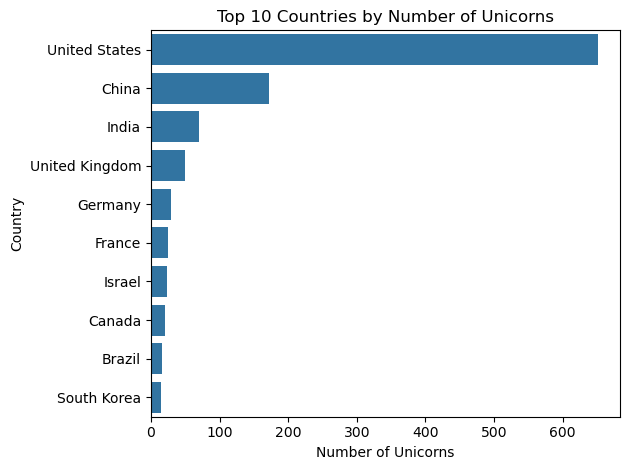

In [16]:
top_countries = df['Country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Countries by Number of Unicorns")
plt.xlabel("Number of Unicorns")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig('figures/fig1_top_countries.png', dpi=150)
plt.show()

## Figure 2: Growth of Unicorns Over Time

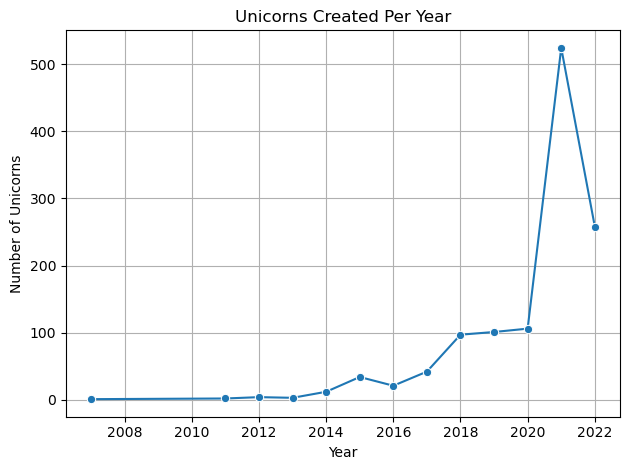

In [17]:
unicorns_per_year = df['Year Joined'].value_counts().sort_index()
sns.lineplot(x=unicorns_per_year.index, y=unicorns_per_year.values, marker='o')
plt.title("Unicorns Created Per Year")
plt.xlabel("Year")
plt.ylabel("Number of Unicorns")
plt.grid(True)
plt.tight_layout()
plt.savefig('figures/fig2_unicorns_per_year.png', dpi=150)
plt.show()

## Figure 3: Most Common Sectors for Unicorns

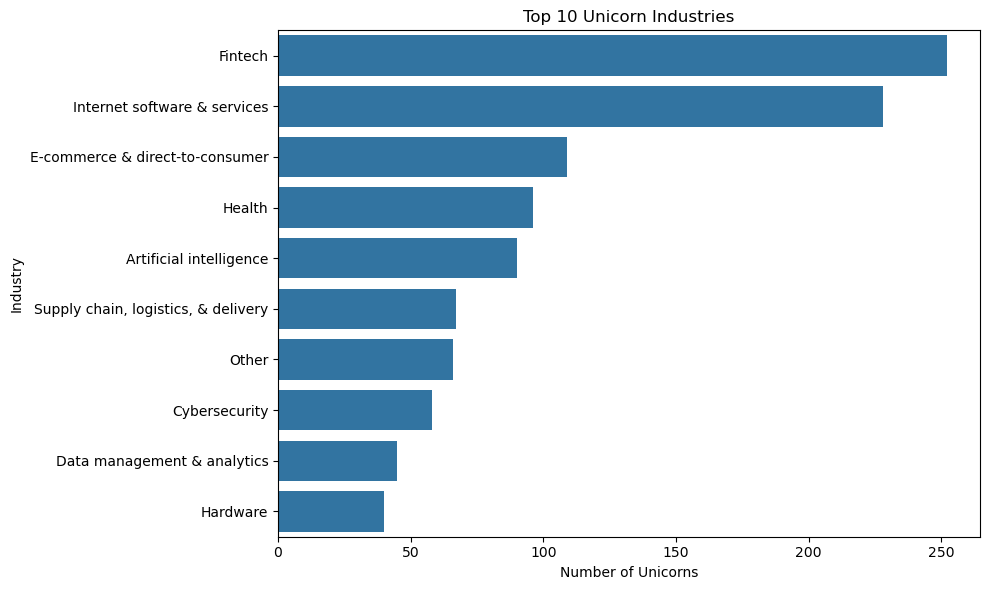

In [18]:
top_industries = df['Industry'].value_counts().head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_industries.values, y=top_industries.index)
plt.title("Top 10 Unicorn Industries")
plt.xlabel("Number of Unicorns")
plt.ylabel("Industry")
plt.tight_layout()
plt.tight_layout()
plt.savefig('figures/fig3_top_industries.png', dpi=150)
plt.show()

## Figure 4: Industries by Average Valuation

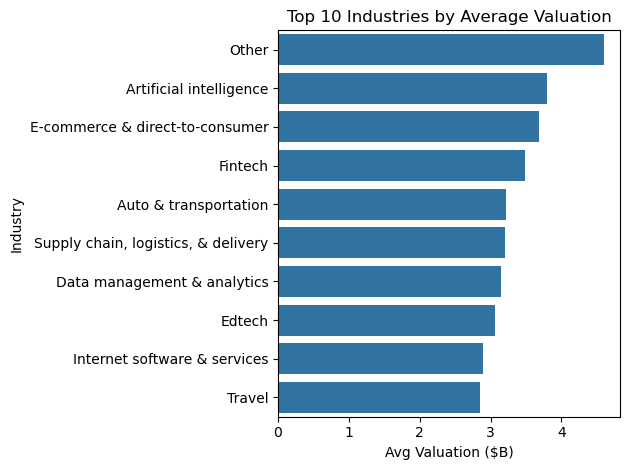

In [19]:
avg_val_by_industry = df.groupby("Industry")["Valuation ($B)"].mean().sort_values(ascending=False).head(10)
sns.barplot(x=avg_val_by_industry.values, y=avg_val_by_industry.index)
plt.title("Top 10 Industries by Average Valuation")
plt.xlabel("Avg Valuation ($B)")
plt.ylabel("Industry")
plt.tight_layout()
plt.savefig('figures/fig4_avg_valuation_by_industry.png', dpi=150)
plt.show()

## Figure 5: Distribution of Unicorn Valuations

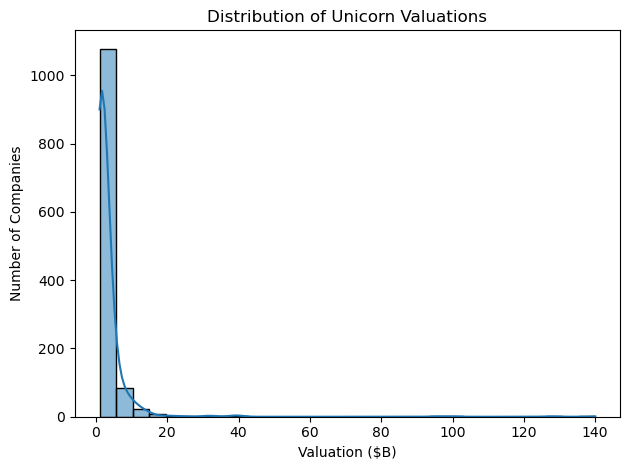

In [20]:
sns.histplot(df['Valuation ($B)'], bins=30, kde=True)
plt.title("Distribution of Unicorn Valuations")
plt.xlabel("Valuation ($B)")
plt.ylabel("Number of Companies")
plt.tight_layout()
plt.savefig('figures/fig5_valuation_distribution.png', dpi=150)
plt.show()

## Figure 6: Correlation Heatmap

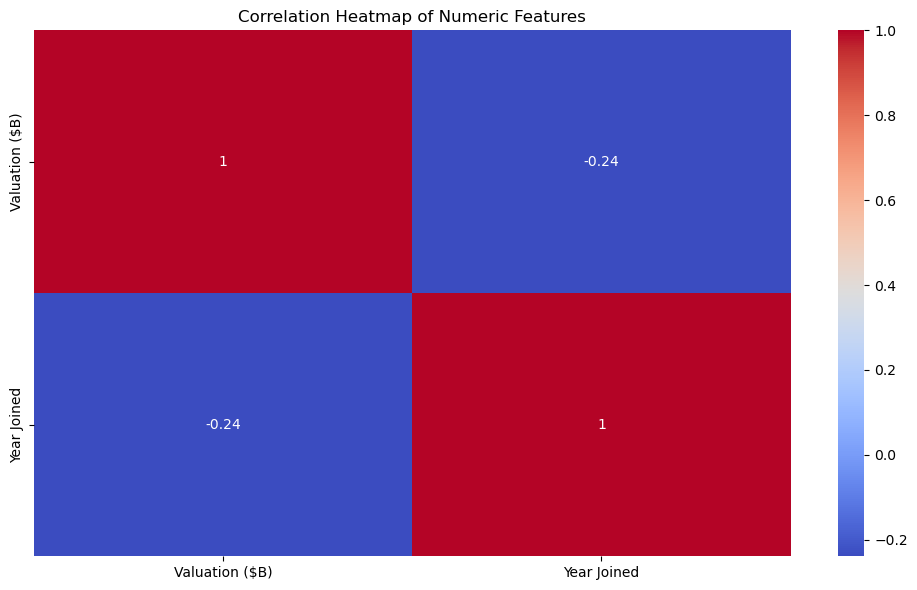

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.savefig('figures/fig6_correlation.png', dpi=150)
plt.show()

## 6. CHECKING THE CONCLUSIONS

The sections above reproduce the original analysis. This section tests its main claims against the data. Where a claim does not hold, the corrected figure is shown.

### 6.1 Data checks

In [22]:
raw = pd.read_csv('data/global_unicorns_data.csv')
cleaned_file = pd.read_csv('data/cleaned_unicorns_data.csv')

print('Raw columns        :', list(raw.columns))
print('Founding year column present?', any('found' in c.lower() for c in raw.columns))
print('Join dates         :', df['Date Joined'].min().date(), 'to', df['Date Joined'].max().date())
print('Full-row duplicates:', df.duplicated().sum())
print('Repeated company names (different companies sharing a name):')
print(df[df['Company'].duplicated(keep=False)][['Company', 'Country', 'Industry', 'Valuation ($B)']].sort_values('Company').to_string(index=False))

# does re-running the cleaning on the raw file reproduce the cleaned CSV that was used in the report?
same = (pd.to_datetime(cleaned_file['Date Joined']).values == df['Date Joined'].values).all() \
       and (cleaned_file['Valuation ($B)'].values == df['Valuation ($B)'].values).all()
print('\nCleaning reproduces the cleaned file (valuation, dates):', same)

Raw columns        : ['Company', 'Valuation ($B)', 'Date Joined', 'Country', 'City', 'Industry', 'Select Investors']
Founding year column present? False
Join dates         : 2007-07-02 to 2022-12-15
Full-row duplicates: 0
Repeated company names (different companies sharing a name):
Company       Country                            Industry  Valuation ($B)
   Bolt United States                             Fintech           11.00
   Bolt       Estonia               Auto & transportation            8.40
 Branch United States         Mobile & telecommunications            4.00
 Branch United States                             Fintech            1.05
 Fabric United States     E-commerce & direct-to-consumer            1.50
 Fabric United States Supply chain, logistics, & delivery            1.00

Cleaning reproduces the cleaned file (valuation, dates): True


**What the checks show**

- **There is no founding-year column**, so the time a company takes to reach unicorn status cannot be computed from this dataset. An earlier conclusion that it takes "approximately 7-9 years" is not supported by the data and is not repeated here.
- **Join dates run from July 2007 to December 2022**, so the file is not a November 2021 snapshot. 2022 contains 258 companies.
- There are no duplicate rows. Three company names repeat (Bolt, Branch, Fabric) but they are different companies.
- Re-running the cleaning on the raw file reproduces the cleaned CSV exactly, so the cleaning steps are fully traceable.
- Two inconsistencies were corrected in section 2: a split `Artificial Intelligence` label (79 + 11 rows) and one row with country and city swapped.

### 6.2 Valuation concentration: checking the figures quoted in the report

Mean $3.21B | median $1.60B | skew 12.48
Valued below $5B        : 87.0%
Valued at $10B or more  : 54 companies (4.5%)
Valued above $10B       : 45 companies
Top 10 companies' share of total valuation: 17.7%
Top 1% (12 companies) share             : 19.1%

Valuation Category
1–2B     683
2–5B     365
5–10B    103
10B+      54


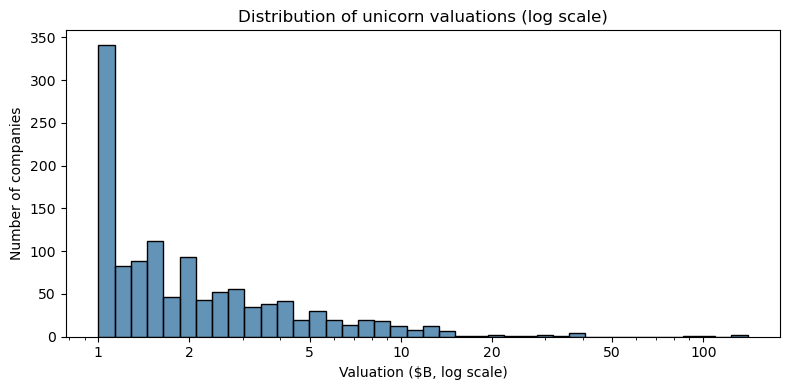

In [23]:
v = df['Valuation ($B)']
print(f"Mean ${v.mean():.2f}B | median ${v.median():.2f}B | skew {v.skew():.2f}")
print(f"Valued below $5B        : {(v < 5).mean()*100:.1f}%")
print(f"Valued at $10B or more  : {(v >= 10).sum()} companies ({(v >= 10).mean()*100:.1f}%)")
print(f"Valued above $10B       : {(v > 10).sum()} companies")
print(f"Top 10 companies' share of total valuation: {v.nlargest(10).sum()/v.sum()*100:.1f}%")
print(f"Top 1% (12 companies) share             : {v.nlargest(12).sum()/v.sum()*100:.1f}%")
print()
print(df['Valuation Category'].value_counts().reindex(['1–2B', '2–5B', '5–10B', '10B+']).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(v, bins=40, log_scale=True, color='#2f6f9f', ax=ax)
ax.set_title('Distribution of unicorn valuations (log scale)')
ax.set_xlabel('Valuation ($B, log scale)'); ax.set_ylabel('Number of companies')
ax.set_xticks([1, 2, 5, 10, 20, 50, 100]); ax.set_xticklabels(['1', '2', '5', '10', '20', '50', '100'])
fig.tight_layout(); fig.savefig('figures/fig7_valuation_log.png', dpi=150); plt.show()

**Result.** The statement that over 80% of unicorns are valued below $5B holds: **87.0%**. The statement that fewer than 20 companies exceed $10B does **not**: **54 companies are valued at $10B or more** (45 strictly above). The skew is real but concentrated in a small group: the ten largest companies hold 17.7% of total valuation.

### 6.3 Which industries are most valuable? Mean vs median

Average valuation is dominated by a few giants (ByteDance in AI, SHEIN in e-commerce, SpaceX in "Other"). The check below compares the mean with the median, and with the mean after removing the ten largest companies.

,companies,mean,mean_excl_top10,median
Industry,,,,
Other,66,4.60,2.27,1.52
Artificial intelligence,90,3.80,2.27,1.55
E-commerce & direct-to-consumer,109,3.69,2.80,1.50
Fintech,252,3.49,2.86,1.72
Auto & transportation,37,3.21,3.21,2.00
"Supply chain, logistics, & delivery",67,3.20,2.66,1.30
Data management & analytics,45,3.15,2.36,1.60
Edtech,32,3.06,3.06,1.60
Internet software & services,228,2.89,2.73,1.67


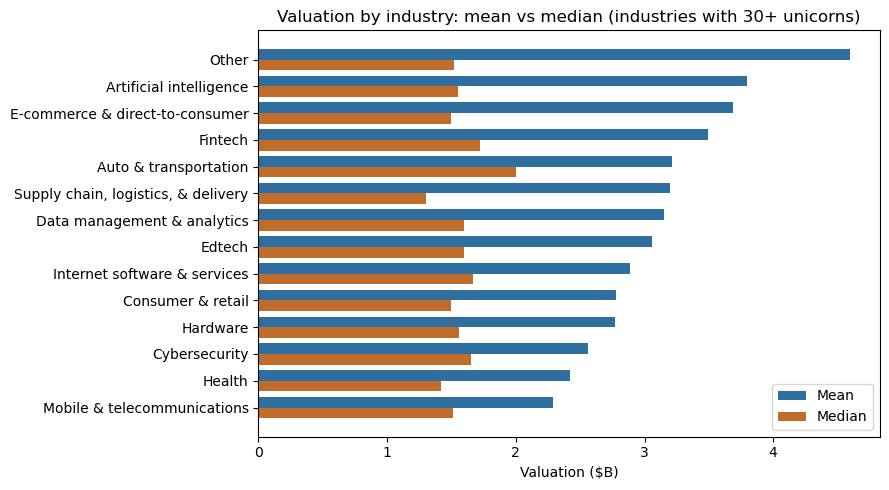

In [24]:
top10_names = df.nlargest(10, 'Valuation ($B)').index
g = df.groupby('Industry')['Valuation ($B)']
ind = pd.DataFrame({
    'companies': g.count(),
    'mean': g.mean(),
    'mean_excl_top10': df.drop(top10_names).groupby('Industry')['Valuation ($B)'].mean(),
    'median': g.median(),
}).sort_values('mean', ascending=False).round(2)
display(ind)

plot = ind[ind['companies'] >= 30].sort_values('mean')
fig, ax = plt.subplots(figsize=(9, 5))
y = range(len(plot))
ax.barh([i + 0.2 for i in y], plot['mean'], height=0.4, label='Mean', color='#2f6f9f')
ax.barh([i - 0.2 for i in y], plot['median'], height=0.4, label='Median', color='#c06c2b')
ax.set_yticks(list(y)); ax.set_yticklabels(plot.index)
ax.set_xlabel('Valuation ($B)'); ax.set_title('Valuation by industry: mean vs median (industries with 30+ unicorns)')
ax.legend(); fig.tight_layout(); fig.savefig('figures/fig8_industry_mean_vs_median.png', dpi=150); plt.show()

**Result.** On the mean, AI and e-commerce rank highest among the five largest industries, as originally reported (AI falls from $4.14B to **$3.80B** once its two labels are merged). But the ranking is driven by a handful of giants:

- Removing the ten largest companies cuts AI from $3.80B to $2.27B and "Other" from $4.60B to $2.27B; **Auto & transportation ($3.21B) and Edtech ($3.06B) then lead**.
- **Medians sit between $1.3B and $2.0B in every industry**; AI's median ($1.55B) is essentially the overall median ($1.60B).

The accurate reading is that industry says little about a typical unicorn's valuation. Which sector a company is in matters less than whether it happens to be one of the very few giants.

### 6.4 Regions: a fuller mapping

The region grouping in section 3 names 16 countries; every other country, including Israel, Australia, Switzerland, Ireland and Italy, falls into "Other". The mapping below covers every country in the data.

In [25]:
region_full = {
    'Americas': ['United States', 'Canada', 'Brazil', 'Mexico', 'Colombia', 'Chile', 'Argentina', 'Ecuador', 'Bermuda'],
    'Europe': ['United Kingdom', 'Germany', 'France', 'Netherlands', 'Sweden', 'Spain', 'Switzerland', 'Ireland',
               'Finland', 'Norway', 'Belgium', 'Croatia', 'Lithuania', 'Austria', 'Denmark', 'Estonia', 'Italy',
               'Luxembourg', 'Czech Republic', 'Liechtenstein'],
    'Asia-Pacific': ['China', 'India', 'South Korea', 'Singapore', 'Indonesia', 'Japan', 'Hong Kong', 'Australia',
                     'Thailand', 'Philippines', 'Vietnam', 'Malaysia'],
    'Middle East & Africa': ['Israel', 'United Arab Emirates', 'Turkey', 'South Africa', 'Nigeria', 'Senegal', 'Seychelles'],
}
lookup = {c: r for r, cs in region_full.items() for c in cs}
unmapped = sorted(set(df['Country']) - set(lookup))
print('Countries not mapped:', unmapped)
df['Region (full)'] = df['Country'].map(lookup)

cmp = pd.DataFrame({
    'companies (original)': df['Region'].value_counts(),
    'median (original)': df.groupby('Region')['Valuation ($B)'].median(),
})
display(cmp.round(2))
res = (df.groupby('Region (full)')['Valuation ($B)']
         .agg(companies='count', share_pct=lambda s: len(s) / len(df) * 100, median='median', mean='mean')
         .sort_values('companies', ascending=False).round(2))
display(res)
print('European companies in the original "Other" group:',
      int(((df['Region'] == 'Other') & (df['Region (full)'] == 'Europe')).sum()))

Countries not mapped: []


,companies (original),median (original)
Region,,
Americas,695,1.69
Asia,284,1.50
Europe,123,1.70
Other,103,1.50


,companies,share_pct,median,mean
Region (full),,,,
Americas,703,58.34,1.65,3.17
Asia-Pacific,307,25.48,1.50,3.44
Europe,161,13.36,1.60,3.08
Middle East & Africa,34,2.82,1.52,2.53


European companies in the original "Other" group: 38


**Result.** The original grouping placed **38 European companies** (Switzerland, Ireland, Norway, Finland, Italy and others) in "Other". With every country mapped, Europe has 161 unicorns (13.4%) instead of 123. Medians range only from $1.50B to $1.65B across regions, so the original conclusion holds: **unicorn counts differ hugely by region, typical valuations do not.**

### 6.5 Unicorn creation and valuation over time

Year Joined,2007,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
companies,1.00,2.00,4.00,3.00,12.00,34.00,21.00,42.00,97.00,101.00,106.00,524.00,258.00
median,1.38,6.20,16.50,1.50,2.90,1.55,1.59,1.56,2.25,2.60,3.20,1.50,1.30


Joined 2017 or later: 93.6% | in 2021 alone: 43.5%
Pearson valuation vs year joined : -0.24
Spearman valuation vs year joined: -0.27


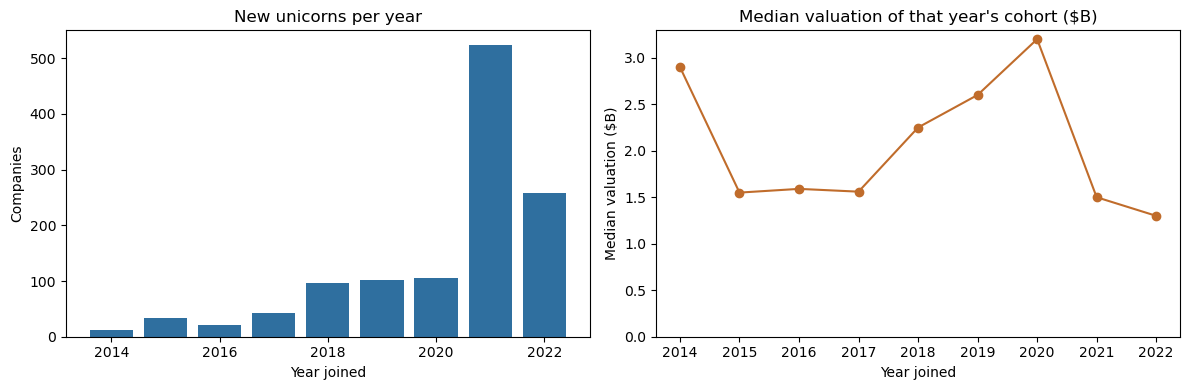

In [26]:
yr = df.groupby('Year Joined')['Valuation ($B)'].agg(companies='count', median='median').round(2)
display(yr.T)
print(f"Joined 2017 or later: {(df['Year Joined'] >= 2017).mean()*100:.1f}% | in 2021 alone: {(df['Year Joined'] == 2021).mean()*100:.1f}%")
print(f"Pearson valuation vs year joined : {df['Valuation ($B)'].corr(df['Year Joined']):+.2f}")
print(f"Spearman valuation vs year joined: {df['Valuation ($B)'].corr(df['Year Joined'], method='spearman'):+.2f}")

since = yr.loc[2014:]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(since.index, since['companies'], color='#2f6f9f'); axes[0].set_title('New unicorns per year')
axes[0].set_xlabel('Year joined'); axes[0].set_ylabel('Companies')
axes[1].plot(since.index, since['median'], marker='o', color='#c06c2b'); axes[1].set_title('Median valuation of that year\'s cohort ($B)')
axes[1].set_xlabel('Year joined'); axes[1].set_ylabel('Median valuation ($B)'); axes[1].set_ylim(0, None)
fig.tight_layout(); fig.savefig('figures/fig9_over_time.png', dpi=150); plt.show()

**Result.**

- **93.6% of unicorns joined in 2017 or later, and 43.5% (524) in 2021 alone.** The 2022 count (258) is roughly half of 2021's.
- The median valuation of each year's cohort fell from **$3.2B (2020) to $1.5B (2021) and $1.3B (2022)**: the 2021 boom added many companies near the $1B threshold.
- Valuation and year joined are **weakly negatively correlated** (Pearson -0.24, Spearman -0.27): later joiners are valued slightly lower. This probably reflects age, since older unicorns have had longer to grow, but the data cannot separate age from cohort effects.

### 6.6 Investors

The original conclusions say investors "play a massive role", but the analysis does not examine them. The `Select Investors` field lists several investors per company, so each is split out and counted (case-insensitive, since the same firm appears with different capitalisation).

,Investor,Unicorns backed
0,Accel,64
1,Andreessen Horowitz,60
2,Tiger Global Management,58
3,Insight Partners,56
4,Sequoia Capital,52
5,Sequoia Capital China,48
6,General Catalyst,43
7,SoftBank Group,43
8,Lightspeed Venture Partners,41
9,Index Ventures,34


Distinct investors listed: 1,375
Investors backing only one unicorn: 911 (66%)
Share of unicorns backed by at least one of the top 10 investors: 36.0%


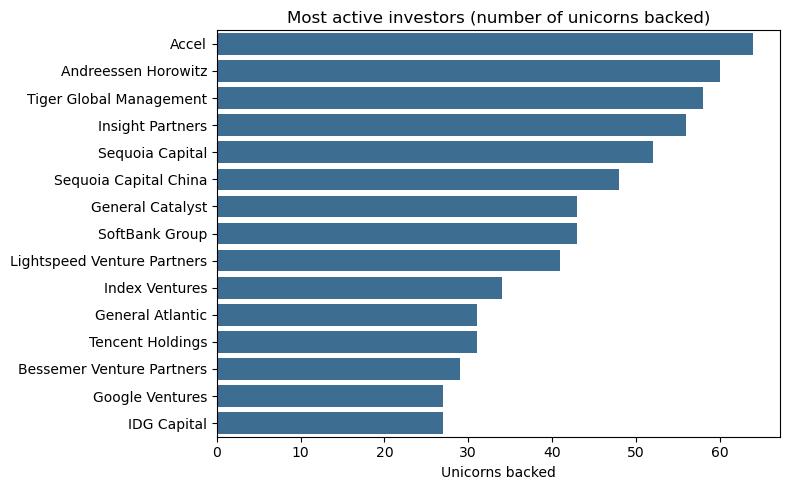

In [27]:
inv = (df[['Company', 'Select Investors']].assign(Investor=lambda d: d['Select Investors'].str.split(','))
         .explode('Investor'))
inv['Investor'] = inv['Investor'].str.strip()
inv = inv[(inv['Investor'] != '') & (inv['Select Investors'] != 'Not disclosed')]
inv['key'] = inv['Investor'].str.lower()
label = inv.groupby('key')['Investor'].agg(lambda s: s.value_counts().index[0])
counts = inv.groupby('key')['Company'].nunique().sort_values(ascending=False)
top = counts.head(15)
table = pd.DataFrame({'Investor': label[top.index].values, 'Unicorns backed': top.values})
display(table)

print(f"Distinct investors listed: {counts.shape[0]:,}")
print(f"Investors backing only one unicorn: {(counts == 1).sum():,} ({(counts == 1).mean()*100:.0f}%)")
top10 = set(counts.head(10).index)
has_top = inv.assign(t=inv['key'].isin(top10)).groupby('Company')['t'].any()
print(f"Share of unicorns backed by at least one of the top 10 investors: {has_top.mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=table['Unicorns backed'], y=table['Investor'], color='#2f6f9f', ax=ax)
ax.set_title('Most active investors (number of unicorns backed)'); ax.set_xlabel('Unicorns backed'); ax.set_ylabel('')
fig.tight_layout(); fig.savefig('figures/fig10_top_investors.png', dpi=150); plt.show()

**Result.** The investor field is highly fragmented: 1,375 distinct investors, **66% of whom back only one unicorn**. A small group of repeat backers (Accel, Andreessen Horowitz, Tiger Global, Insight Partners, Sequoia) appears across many companies, and **the top ten investors are among the backers of 36.0% of all unicorns**. This supports describing the ecosystem as having a concentrated core of repeat investors. It does not show that investors *cause* high valuations, and the field only lists "select" investors, not full cap tables.

## 7. SUMMARY

**What holds**
- The US (54.0%), China (14.3%) and India (5.8%) account for about 74% of unicorns.
- Valuations are extremely right-skewed (skewness 12.48; mean $3.21B vs median $1.60B); 87% are below $5B.
- Unicorn creation surged from 2017 and peaked in 2021, then halved in 2022.
- Typical valuations are similar across regions.

**What the checks changed**
- More companies sit at the top end than reported: 54 at $10B+, not "fewer than 20".
- Industry averages are outlier-driven. By median, no industry stands out.
- Time-to-unicorn cannot be computed from this data, and the file extends to December 2022.
- Merging the AI label (+11 companies) and fixing the regions (+38 European companies) are small corrections that do not alter the main picture.